# 02.5 - How the spectrum was computed, and what it costs

Notebook 02 extracted the object-space modes of the full-scan Jacobian one way: accumulate
$A^{\mathsf T}A$ over the whole object grid and take its top $k$ eigenpairs. It then read
physics off the result. That reading is only worth as much as the claim that the modes belong
to **the operator** and not to the algorithm that found them.

This notebook is where that claim is checked, and where the costs that notebook 02 asserts in
passing are measured. Three routes to the same modes:

| | domain | how | returns |
|---|---|---|---|
| **A** | whole object grid, $N = 63\,001$ | explicit Gram, subspace iteration | top $k$ |
| **B** | cropped window, $W^2 = 8\,836$ | structured Gram via FFT tables, complete `eigh` | **all** of it |
| **C** | whole object grid | no Gram at all, matrix-free subspace iteration | top $k$ |

They are complementary rather than redundant. A is the baseline. B is the only one that
returns the blind end of the spectrum, because its domain is small enough to diagonalize
completely and to afford float64 - but it answers a *different*, smaller question, and its
frequency spectra carry an artefact that must not be read as physics. C keeps the full domain
and drops the Gram, which is where half the available digits were being spent.

The questions, in order:

1. Do the three agree where they should, and do the two bounds that relate them hold?
2. The leading modes are crowded. Are they *degenerate* - is an individual mode picture
   meaningful at all?
3. What does the $k = 1024$ cap cost on the quantity notebook 02 actually plots?
4. What did weighting by $\sigma^2$ change, relative to the thresholded sum it replaced?
5. Where does the arithmetic floor sit, and which end of each spectrum is trustworthy?

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

NOTEBOOK_DIR = Path.cwd()
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import fft_structured_gram as fsg
import scan_jacobian_utils as sju

torch.backends.cuda.matmul.allow_tf32 = False

print("torch        :", torch.__version__)
if torch.cuda.is_available():
    free_bytes, total_bytes = torch.cuda.mem_get_info()
    print("cuda device  :", torch.cuda.get_device_name(0),
          f"({total_bytes / 1e9:.1f} GB total, {free_bytes / 1e9:.1f} GB free)")

torch        : 2.14.1+cu130
cuda device  : NVIDIA GeForce RTX 5090 (33.7 GB total, 1.9 GB free)


## Configuration

The experiment is **exactly** notebook 02's - same phase, probe, scan and solver settings, so
that method A's spectrum is read from the same cache file and the comparison is against the
same numbers that notebook plots. Only the two extra methods add settings of their own.

`GRAM_WINDOW_WIDTH_PX` must keep method B's window strictly inside the scanned region; the
cell below asserts it and prints the largest width that fits.

In [2]:
config = sju.ExperimentConfig(
    phase_cache_path=NOTEBOOK_DIR.parent / "bcenters_base_excited_phases_wide_fov.pkl",
    phase_cache_key_base="base",
    acc_voltage_ev=60e3,
    probe_semiangle_mrad=30.0,
    probe_defocus_ang=0.0,
    slice_thickness_ang=1.0,
    hbn_lattice_constant_ang=2.504,
    scan_step_size_ang=0.5,
    scan_region_start=(7.0, 7.0),
    scan_region_end=(17.0, 17.0),
    scan_endpoint=False,
    device=sju.pick_device(min_free_gb=2.0),
)

# --- method A: as notebook 02, read from its cache -------------------------------
GRAM_PRECISION = "float32"
GRAM_ROW_BLOCK = 4096
N_MODES = 1024
N_OVERSAMPLE = 256
N_ITERATIONS = 20
RANDOM_SEED = 0
CACHE_DIR = NOTEBOOK_DIR / "data"

# --- method B: the cropped window ------------------------------------------------
GRAM_WINDOW_WIDTH_PX = 94        # square window of object pixels, centred on the field of view
WINDOW_PRECISION = "float64"     # the window is small enough to afford it
WINDOW_SYMMETRIC = True          # compute the lower triangle only and mirror it

# --- method C: matrix-free -------------------------------------------------------
# C is the expensive one and the only step that needs real device memory.  It is skipped
# unless the GPU can host it; every section below reports whatever methods are present.
FREE_SCAN_CHUNK = 2              # scan positions whose detector response is held at once
FREE_BASIS_BLOCK = 256           # sketch columns transformed at a time - caps peak memory
FREE_MIN_FREE_GB = 6.0           # device memory C needs at these settings
RUN_MATRIX_FREE = (config.device == "cuda"
                   and torch.cuda.mem_get_info()[0] / 1e9 >= FREE_MIN_FREE_GB)

SIGMA_THRESHOLDS = (0.5, 0.1)    # tau cuts, used only in the "what the weighting changed" section
N_MODES_SHOWN = 6

print("device                :", config.device)
print("window                :", f"{GRAM_WINDOW_WIDTH_PX}x{GRAM_WINDOW_WIDTH_PX} px,",
      WINDOW_PRECISION, "complete spectrum")
print("matrix-free (method C):", "will run" if RUN_MATRIX_FREE else
      f"SKIPPED - needs {FREE_MIN_FREE_GB:.0f} GB of free device memory")

device: cpu   (only 1.9 GB free of 33.7 GB on the GPU, 2.0 GB asked for)
device                : cpu
window                : 94x94 px, float64 complete spectrum
matrix-free (method C): SKIPPED - needs 6 GB of free device memory


In [3]:
experiment = sju.build_experiment(config)
e = experiment
spectral = sju.SpectralGrid(e)

cache_path = sju.spectrum_cache_path(
    CACHE_DIR, e, config,
    (GRAM_PRECISION, GRAM_ROW_BLOCK, N_MODES, N_OVERSAMPLE, N_ITERATIONS, RANDOM_SEED),
)
if not cache_path.exists():
    raise RuntimeError(f"method A's spectrum is not cached at {cache_path.name}. "
                       "Run notebook 02 first, on a machine with a free GPU.")

stored = np.load(cache_path)
results = {}
results["A"] = dict(
    name="A - dense Gram, whole object grid",
    sigma=stored["sigma"], modes=stored["modes"], origin=(0, 0),
    extent=e.object_extent_ang, n_domain=e.n_object_pixels, complete=False,
    seconds=float(stored["build_seconds"]) + float(stored["solve_seconds"]),
    numerical_floor=1e-5, notes=f"float32, {N_MODES} of {e.n_object_pixels:,} modes",
)
seed_overlap = stored["seed_overlap"]

print(f"object grid           : {e.n_object_y} x {e.n_object_x} = {e.n_object_pixels:,} px")
print(f"scan                  : {e.scan_shape} = {e.n_scan_positions} positions "
      f"at {e.realised_scan_step_ang:.3f} A")
print(f"method A, from cache  : sigma_1 = {results['A']['sigma'][0]:.6e}, "
      f"{len(results['A']['sigma'])} modes, built in "
      f"{float(stored['build_seconds']):.0f} s using {float(stored['peak_gb']):.1f} GB")

object grid           : 251 x 251 = 63,001 px
scan                  : (20, 20) = 400 positions at 0.500 A
method A, from cache  : sigma_1 = 6.510881e-03, 1024 modes, built in 700 s using 27.9 GB


---

# B. The cropped window

Method A pays $2N^2M$ flops per position and 15.9 GB of device memory because $N$ is every
pixel of the object. Most of those pixels are not the ones in question: an excitation is
localized, and the quantity of interest is which perturbations *of a particular region* the
scan can see. Cropping the Gram to a window of object pixels attacks both costs at once, and
it changes the problem in ways that have to be stated.

**The window must lie strictly inside the scanned region.** The scan positions are where probe
*centres* go, and illumination extends about a probe radius beyond them. A window placed at
the edge of the scan would be covered unevenly - some of its pixels seen by many positions,
others by few - and $A^{\mathsf T}A$ carries that weighting directly into its leading modes,
which would then report the scan bookkeeping rather than the optics.

**How it is built.** The restriction makes a structured accumulation worthwhile. Writing
$A[k,p] = -2\,\mathrm{Im}(\Psi_k^{*}F[k,p]\psi_p)$ and using
$\mathrm{Im}(a)\mathrm{Im}(b) = \tfrac12[\mathrm{Re}(a\bar b) - \mathrm{Re}(ab)]$, the sum over
detector pixels collapses in closed form,

$$G[p,q] = \sum_k A[k,p]A[k,q]
= 2\,\mathrm{Re}\!\left[\psi_p\bar\psi_q\,T_1(p-q)\right] - 2\,\mathrm{Re}\!\left[\psi_p\psi_q\,T_2(p+q)\right],$$

because $F[k,p]\overline{F[k,q]}$ depends only on $p-q$ and $F[k,p]F[k,q]$ only on $p+q$. The
two lookup tables are single transforms of detector-plane quantities, zero-padded back onto the
object grid, $T_1 = \mathcal F\{\mathrm{zeropad}(|\Psi|^2)\}$ and
$T_2 = \mathcal F\{\mathrm{zeropad}(\bar\Psi^{\,2})\}$, so one position costs two FFTs and two
outer products - about $4N^2$ flops instead of $2N^2M$. This is an identity, not an
approximation; it is also *more* accurate than the GEMM at equal precision, because the sum over
the $M$ detector pixels is performed by the FFT rather than by accumulating $M$ rounded products.

**What it buys, and what it discards.** The dimensionality falls from $63\,001$ to $94^2 = 8\,836$,
which is 0.62 GB in float64 and a complete `eigh` in seconds. So this is the only one of the
three that returns the **entire** spectrum - the roll-off and the blind end included - and the
only one that can afford float64. What it discards is any perturbation with support crossing the
window edge: the restriction implicitly asserts that the phase perturbation is exactly zero
outside, so a mode of the full problem that extends past the boundary is not approximated by this
calculation, it is *excluded* from it. Cropping the Gram is exactly taking a principal submatrix
of the whole-object Gram, and Cauchy's interlacing theorem then bounds every eigenvalue of the
restriction by the corresponding eigenvalue of the whole,

$$\lambda_i(G_{\mathrm{window}}) \le \lambda_i(G_{\mathrm{whole}}),$$

so the window can only understate sensitivity, never overstate it. It is the right tool for a
localized excitation and the wrong one for an extended one.

In [4]:
window_real_dtype, window_complex_dtype = fsg.dtypes_for(WINDOW_PRECISION)
window_rows, window_cols = fsg.window_indices(e.n_object_y, e.n_object_x, GRAM_WINDOW_WIDTH_PX)
window_origin = (int(window_rows[0]), int(window_cols[0]))
n_window_pixels = len(window_rows) * len(window_cols)
window_extent_ang = [float(e.object_x_ang[window_cols[0]]), float(e.object_x_ang[window_cols[-1]]),
                     float(e.object_y_ang[window_rows[0]]), float(e.object_y_ang[window_rows[-1]])]


# The containment the section text requires, asserted rather than assumed.  The largest
# admissible width is computed rather than guessed: a centred window grows in steps of two
# pixels and the scan box is not centred on the grid to within a pixel.
def window_fits(width):
    row0, col0 = (e.n_object_y - width) // 2, (e.n_object_x - width) // 2
    return (e.object_x_ang[col0] >= e.scan_box_ang[0]
            and e.object_x_ang[col0 + width - 1] <= e.scan_box_ang[1]
            and e.object_y_ang[row0] >= e.scan_box_ang[2]
            and e.object_y_ang[row0 + width - 1] <= e.scan_box_ang[3])


largest_admissible_width = max(w for w in range(8, min(e.n_object_y, e.n_object_x) + 1)
                               if window_fits(w))
inside = window_fits(GRAM_WINDOW_WIDTH_PX)
window_coverage = e.coverage[np.ix_(window_rows, window_cols)]

print(f"window                     : {GRAM_WINDOW_WIDTH_PX}x{GRAM_WINDOW_WIDTH_PX} object px "
      f"= {GRAM_WINDOW_WIDTH_PX * e.object_sampling_ang[0]:.2f} x "
      f"{GRAM_WINDOW_WIDTH_PX * e.object_sampling_ang[1]:.2f} A")
print(f"window extent [A]          : x {window_extent_ang[0]:.2f}-{window_extent_ang[1]:.2f},"
      f"  y {window_extent_ang[2]:.2f}-{window_extent_ang[3]:.2f}")
print(f"scanned region [A]         : x {e.scan_box_ang[0]:.2f}-{e.scan_box_ang[1]:.2f},"
      f"  y {e.scan_box_ang[2]:.2f}-{e.scan_box_ang[3]:.2f}")
print(f"window inside the scan     : {inside}")
print(f"largest admissible width   : {largest_admissible_width} px "
      f"({largest_admissible_width * e.object_sampling_ang[0]:.2f} A)")
assert inside, (f"the window must lie strictly inside the scanned region; the largest "
                f"centred width that fits is {largest_admissible_width} px")
print(f"coverage inside the window : max/min = "
      f"{window_coverage.max() / window_coverage.min():.3f}"
      f"   (1.000 would be perfectly uniform illumination)")
print(f"dimensionality             : {e.n_object_pixels:,} -> {n_window_pixels:,} "
      f"({n_window_pixels / e.n_object_pixels:.1%} of the whole-object problem)")
print(f"Gram                       : {n_window_pixels:,}^2 "
      f"({(8 if WINDOW_PRECISION == 'float64' else 4) * n_window_pixels ** 2 / 1e9:.2f} GB)")
print(f"flops/position             : {4 * n_window_pixels ** 2:.2e} structured  vs  "
      f"{2 * n_window_pixels ** 2 * e.n_detector_pixels:.2e} as a matrix product "
      f"({e.n_detector_pixels / 2:.0f}x)\n")

start_time = time.time()
window_gram = fsg.structured_gram_accumulate(
    e.exit_wave_by_scan, e.camera_wave_by_scan, window_rows, window_cols,
    window_real_dtype, window_complex_dtype,
    row_block=GRAM_ROW_BLOCK, symmetric=WINDOW_SYMMETRIC,
    progress_every=max(1, e.n_scan_positions // 4),
)
window_build_seconds = time.time() - start_time
print(f"\nstructured Gram accumulated in {window_build_seconds:.1f} s")

start_time = time.time()
eigenvalues, eigenvectors = torch.linalg.eigh(window_gram)
window_sigma = eigenvalues.flip(0).clamp(min=0).sqrt()
window_modes = eigenvectors.flip(1).T.reshape(
    n_window_pixels, GRAM_WINDOW_WIDTH_PX, GRAM_WINDOW_WIDTH_PX)
flat = window_modes.reshape(n_window_pixels, -1)
peak_sign = torch.sign(flat.gather(1, flat.abs().argmax(1, keepdim=True)))
window_modes = (window_modes * peak_sign[:, None]).to(torch.float32).cpu().numpy()
window_sigma = window_sigma.cpu().numpy()
window_solve_seconds = time.time() - start_time
del window_gram, eigenvalues, eigenvectors, flat

window_floor = 1e-8 if WINDOW_PRECISION == "float64" else 1e-5
n_above_floor = int((window_sigma > window_floor * window_sigma[0]).sum())
print(f"complete eigh of {n_window_pixels:,}^2 in {window_solve_seconds:.1f} s")
print(f"sigma_1                    : {window_sigma[0]:.6e}")
print(f"modes above the {window_floor:.0e} floor : {n_above_floor} / {n_window_pixels} "
      f"({n_above_floor / n_window_pixels:.1%})")

results["B"] = dict(
    name=f"B - cropped window ({GRAM_WINDOW_WIDTH_PX} px)",
    sigma=window_sigma, modes=window_modes, origin=window_origin,
    extent=window_extent_ang, n_domain=n_window_pixels, complete=True,
    seconds=window_build_seconds + window_solve_seconds,
    numerical_floor=window_floor, notes=f"{WINDOW_PRECISION}, complete spectrum",
)

window                     : 94x94 object px = 9.02 x 9.02 A
window extent [A]          : x 7.49-16.42,  y 7.49-16.42
scanned region [A]         : x 7.00-16.50,  y 7.00-16.50
window inside the scan     : True
largest admissible width   : 94 px (9.02 A)
coverage inside the window : max/min = 1.407   (1.000 would be perfectly uniform illumination)
dimensionality             : 63,001 -> 8,836 (14.0% of the whole-object problem)
Gram                       : 8,836^2 (0.62 GB)
flops/position             : 3.12e+08 structured  vs  2.21e+12 as a matrix product (7080x)



      100/400 positions (  51.6 s)


      200/400 positions ( 102.3 s)


      300/400 positions ( 154.4 s)


      400/400 positions ( 206.1 s)



structured Gram accumulated in 206.1 s


complete eigh of 8,836^2 in 13.6 s
sigma_1                    : 6.504957e-03
modes above the 1e-08 floor : 8327 / 8836 (94.2%)


---

# C. Matrix-free: never form the Gram

Methods A and B both build $A^{\mathsf T}A$ and then diagonalize it. The Gram is what makes the
problem tractable, and it is also the one avoidable source of error in it: squaring the operator
squares the condition number, so half the available digits are spent before the eigensolver
starts. Method A had to accept a $10^{-5}\sigma_1$ floor because a float64 Gram on the whole
object grid does not fit in memory. This section keeps the whole grid and drops the Gram.

Subspace iteration needs only the *action* of the operator, never its entries, and both actions
are available in closed form as FFTs on the object grid:

$$A_{\mathbf R}h = -2\,\mathrm{Im}\!\left[\overline{\Psi_{0,\mathbf R}}\,
\mathrm{crop}\,\mathcal F\{\psi_{0,\mathbf R}h\}\right], \qquad
A_{\mathbf R}^{\mathsf T}g = 2\,\mathrm{Re}\!\left[\psi_{0,\mathbf R}\,
\mathcal F\{\mathrm{zeropad}(j\,g\,\overline{\Psi_{0,\mathbf R}})\}\right],$$

the second following from the first because the centred DFT matrix is symmetric and zero-padding
is the adjoint of the crop. $Q$ is the sketch basis, $N \times (k+p)$ - here
$63\,001 \times 1280$ - whose columns are orthonormal real phase perturbations. Iterating
$Q \leftarrow \mathrm{qr}(\sum_{\mathbf R}A_{\mathbf R}^{\mathsf T}(A_{\mathbf R}Q))$ drives it
onto the leading right-singular subspace; the Rayleigh-Ritz step then separates the modes out of
it. No matrix larger than $N \times (k+p)$ ever exists - 0.3 GB here against 15.9 GB for the Gram.

**Both directions change.** *Better:* the Ritz step is taken on the small projected matrix
$T = Q^{\mathsf T}A^{\mathsf T}AQ$, so the condition number that gets squared is that *of the
retained subspace*, around $\sigma_1/\sigma_k \approx 10$ here, rather than that of the full
operator, which spans eight decades. Method A's float32 floor simply does not arise.
*Worse:* only the leading $k$ are available at all, and a Rayleigh-Ritz value is a lower bound,
$\hat\sigma_i \le \sigma_i$, with equality only at convergence. The spectrum is dense near the
top, so the trailing modes of the retained block converge slowest and are the ones to distrust -
which is what the printed Ritz drift is for.

In [5]:
if RUN_MATRIX_FREE:
    free_exit_wave = e.exit_wave_by_scan.to(torch.complex64)
    free_camera_wave = e.camera_wave_by_scan.to(torch.complex64)

    def gram_action(basis, chunk=FREE_SCAN_CHUNK, basis_block=FREE_BASIS_BLOCK,
                    want_projection=False):
        '''sum_R A_R^T (A_R Q), and optionally sum_R (A_R Q)^T (A_R Q).

        The detector-space response of a scan chunk is consumed by the adjoint before the
        next chunk is read, and the sketch columns are processed in blocks, so peak memory
        is set by ``chunk * basis_block`` and never by the number of positions or modes.
        '''
        out = torch.zeros_like(basis)
        projection = (torch.zeros(len(basis), len(basis), device=basis.device,
                                  dtype=torch.float32) if want_projection else None)
        for start in range(0, e.n_scan_positions, chunk):
            span = slice(start, min(start + chunk, e.n_scan_positions))
            responses = []
            for first in range(0, len(basis), basis_block):
                columns = slice(first, min(first + basis_block, len(basis)))
                response = -2.0 * (
                    torch.conj(free_camera_wave[span])[:, None]
                    * e.crop_to_detector(e.centered_dft_torch(
                        free_exit_wave[span][:, None] * basis[columns][None]))
                ).imag
                if want_projection:
                    responses.append(response)
                weighted = (1j * response.to(torch.complex64)
                            * torch.conj(free_camera_wave[span])[:, None])
                padded = torch.zeros(weighted.shape[0], weighted.shape[1],
                                     e.n_object_y, e.n_object_x,
                                     device=basis.device, dtype=torch.complex64)
                padded[..., e.detector_row_start:e.detector_row_start + e.n_detector_y,
                       e.detector_col_start:e.detector_col_start + e.n_detector_x] = weighted
                out[columns] += (2.0 * (free_exit_wave[span][:, None]
                                        * e.centered_dft_torch(padded)).real).sum(0)
                del response, weighted, padded
            if want_projection:
                full = torch.cat(responses, dim=1)
                projection += torch.einsum("mkij,mlij->kl", full, full)
                del responses, full
        return (out, projection) if want_projection else out

    def matrix_free_top_k(n_modes, n_oversample, n_iterations, seed):
        sketch = n_modes + n_oversample
        generator = torch.Generator(device=config.device).manual_seed(seed)
        basis = torch.randn(sketch, e.n_object_y, e.n_object_x, device=config.device,
                            dtype=torch.float32, generator=generator)
        basis = torch.linalg.qr(basis.reshape(sketch, -1).T)[0].T.reshape(
            sketch, e.n_object_y, e.n_object_x)

        def ritz(basis):
            _, projection = gram_action(basis, want_projection=True)
            projection = 0.5 * (projection + projection.T)
            return torch.linalg.eigh(projection)

        previous = None
        for iteration in range(n_iterations):
            applied = gram_action(basis).reshape(sketch, -1).T
            basis = torch.linalg.qr(applied)[0].T.reshape(sketch, e.n_object_y, e.n_object_x)
            if iteration == n_iterations - 2:
                previous = ritz(basis)[0].flip(0)[:n_modes].clamp(min=0).sqrt()
            print(f"  iteration {iteration + 1:3d}/{n_iterations}", end="\r", flush=True)

        values, vectors = ritz(basis)
        sigma = values.flip(0)[:n_modes].clamp(min=0).sqrt()
        modes = (vectors.flip(1)[:, :n_modes].T @ basis.reshape(sketch, -1)
                 ).reshape(n_modes, e.n_object_y, e.n_object_x)
        drift = (float(((sigma - previous).abs() / sigma[0]).max())
                 if previous is not None else np.nan)
        return sigma, modes, drift

    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    start_time = time.time()
    free_sigma, free_modes, free_drift = matrix_free_top_k(
        N_MODES, N_OVERSAMPLE, N_ITERATIONS, RANDOM_SEED)
    torch.cuda.synchronize()
    free_seconds = time.time() - start_time

    flat = free_modes.reshape(N_MODES, -1)
    peak_sign = torch.sign(flat.gather(1, flat.abs().argmax(1, keepdim=True)))
    free_modes = (free_modes * peak_sign[:, None]).cpu().numpy()
    free_sigma = free_sigma.cpu().numpy()
    free_peak_gb = torch.cuda.max_memory_allocated() / 1e9
    del flat
    torch.cuda.empty_cache()

    print(f"\nmatrix-free top-{N_MODES} in {free_seconds:.1f} s "
          f"({N_ITERATIONS} iterations, {N_OVERSAMPLE} oversampled)")
    print(f"peak device memory                 : {free_peak_gb:.2f} GB"
          f"   (the Gram alone would be {4 * e.n_object_pixels ** 2 / 1e9:.1f} GB)")
    print(f"Ritz drift over the last iteration : {free_drift:.2e} x sigma_1")
    print(f"sigma_1                            : {free_sigma[0]:.6e}")

    results["C"] = dict(
        name="C - matrix-free, whole object grid",
        sigma=free_sigma, modes=free_modes, origin=(0, 0), extent=e.object_extent_ang,
        n_domain=e.n_object_pixels, complete=False, seconds=free_seconds,
        numerical_floor=None, notes=f"no Gram, {N_MODES} of {e.n_object_pixels:,} modes",
    )
else:
    print(f"method C skipped: it needs ~{FREE_MIN_FREE_GB:.0f} GB of free device memory and "
          f"the device is {config.device!r}.")
    print("Everything below reports whichever methods are present, so the notebook still runs.")

method C skipped: it needs ~6 GB of free device memory and the device is 'cpu'.
Everything below reports whichever methods are present, so the notebook still runs.


In [6]:
# derived quantities every section below shares, computed once per method present
for key, result in results.items():
    result["qbar"] = spectral.mode_mean_frequency(result["modes"], result["origin"])
    result["density"] = spectral.sensitivity_density(result["modes"], result["sigma"],
                                                     result["origin"])
    result["density_radial"] = spectral.angular_integral(result["density"])
    result["frobenius"] = float((result["sigma"].astype(np.float64) ** 2).sum())
    result["degeneracy"] = sju.degeneracy_counts(result["sigma"])

present = [k for k in ("A", "B", "C") if k in results]
styles = {"A": ("#0072B2", "-"), "B": ("#D55E00", "--"), "C": ("#009E73", ":")}
print("methods present:", ", ".join(results[k]["name"] for k in present))

methods present: A - dense Gram, whole object grid, B - cropped window (94 px)


## The leading modes, method by method

The same question asked of each domain. B's modes live on the 94 px window and are shown on it;
A's and C's cover the whole grid, with the scanned region dashed. If the three are finding the
same operator, the leading modes should be the same kind of object - and where B's differ, the
window edge should be the reason.

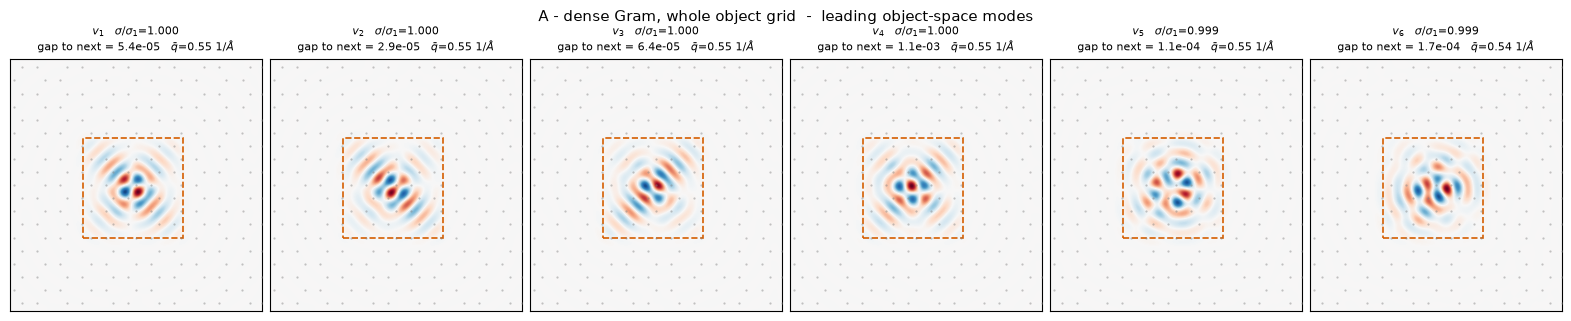

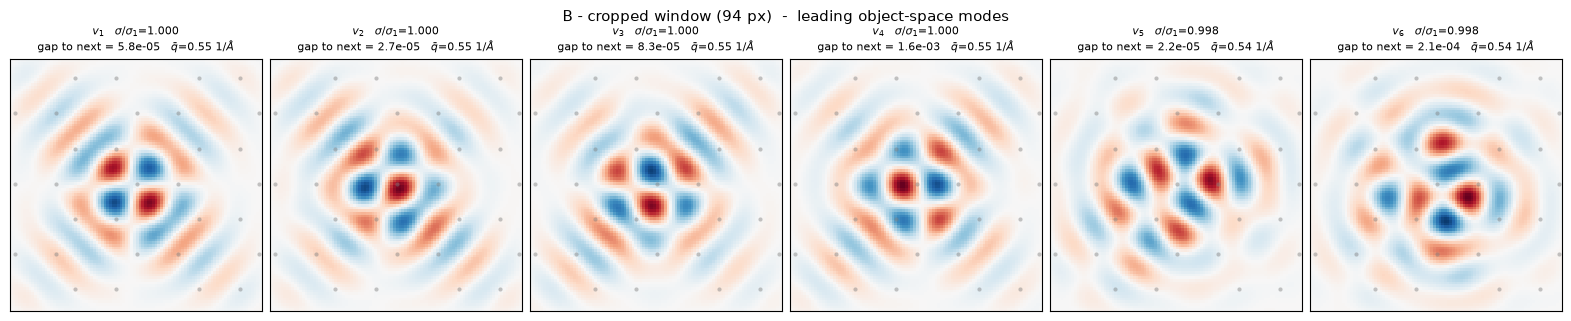

In [7]:
for key in present:
    result = results[key]
    gap = sju.relative_gap(result["sigma"])
    fig, axes = plt.subplots(1, N_MODES_SHOWN, figsize=(2.6 * N_MODES_SHOWN, 3.2),
                             constrained_layout=True)
    limit = float(np.abs(result["modes"][:N_MODES_SHOWN]).max())
    for column in range(N_MODES_SHOWN):
        ax = axes[column]
        ax.imshow(result["modes"][column], extent=result["extent"], origin="lower",
                  cmap="RdBu_r", vmin=-limit, vmax=limit, interpolation="nearest")
        sju.draw_atoms_on(ax, e, markersize=1.6 if result["origin"] == (0, 0) else 3.0)
        if result["origin"] == (0, 0):
            ax.add_patch(plt.Rectangle(
                (e.scan_box_ang[0], e.scan_box_ang[2]),
                e.scan_box_ang[1] - e.scan_box_ang[0], e.scan_box_ang[3] - e.scan_box_ang[2],
                fill=False, edgecolor="#D55E00", linewidth=1.2, linestyle="--"))
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"$v_{{{column + 1}}}$   "
                     f"$\\sigma/\\sigma_1$={result['sigma'][column] / result['sigma'][0]:.3f}\n"
                     f"gap to next = {gap[column]:.1e}   "
                     f"$\\bar q$={result['qbar'][column]:.2f} 1/$\\AA$", fontsize=8)
    fig.suptitle(f"{result['name']}  -  leading object-space modes", fontsize=11)
    plt.show()

## The two bounds, checked

Method A is the baseline. Both alternatives should sit below it, for the two reasons already
given: the window Gram is a principal submatrix of the whole-object Gram, so Cauchy interlacing
applies; and matrix-free subspace iteration returns Rayleigh-Ritz values, which underestimate
until convergence. A violation of either bound by more than the numerical floor would mean one
of the three operators is not the operator it claims to be.

One caveat on what the check can prove. The baseline is itself obtained by subspace iteration,
so its own $\sigma_i$ are lower bounds too, and they are loosest exactly where the iteration has
converged least - at the trailing end of the retained block. A small excess of B or C over A
there is evidence that **A** has not converged, not that the bound has failed. The Ritz drifts
printed in each section say which end to trust.

sigma_1   A : 6.510881e-03
          B : 6.504957e-03   (0.9991 x A)

B/A over the first 1024 modes : min 0.0716, median 0.1313, max 0.9991
   Cauchy interlacing  lambda_i(B) <= lambda_i(A) : HOLDS   (largest B/A = 0.999090)


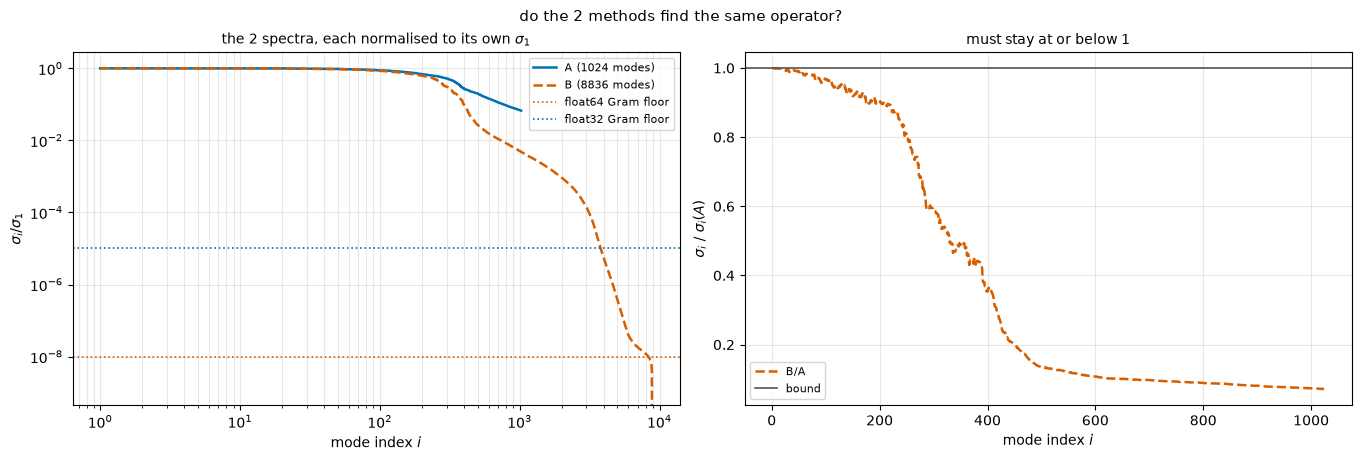

In [8]:
sigma_a = results["A"]["sigma"]
tolerance = 1e-4

print(f"sigma_1   A : {sigma_a[0]:.6e}")
for key in present:
    if key == "A":
        continue
    print(f"          {key} : {results[key]['sigma'][0]:.6e}"
          f"   ({results[key]['sigma'][0] / sigma_a[0]:.4f} x A)")
print()

ratios = {}
for key in present:
    if key == "A":
        continue
    n = min(len(sigma_a), len(results[key]["sigma"]))
    ratios[key] = results[key]["sigma"][:n] / sigma_a[:n]
    label = ("Cauchy interlacing  lambda_i(B) <= lambda_i(A)" if key == "B"
             else "Ritz bound          sigma_i(C) <= sigma_i(A)")
    print(f"{key}/A over the first {n} modes : min {ratios[key].min():.4f}, "
          f"median {np.median(ratios[key]):.4f}, max {ratios[key].max():.4f}")
    print(f"   {label} : "
          f"{'HOLDS' if ratios[key].max() <= 1.0 + tolerance else 'VIOLATED'}"
          f"   (largest {key}/A = {ratios[key].max():.6f})")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5), constrained_layout=True)
for key in present:
    colour, dash = styles[key]
    axes[0].semilogy(np.arange(1, len(results[key]["sigma"]) + 1),
                     results[key]["sigma"] / results[key]["sigma"][0],
                     linestyle=dash, color=colour, linewidth=1.8,
                     label=f"{key} ({len(results[key]['sigma'])} modes)")
if results["B"]["numerical_floor"]:
    axes[0].axhline(results["B"]["numerical_floor"], color="#D55E00", linestyle=":",
                    linewidth=1.2, label="float64 Gram floor")
axes[0].axhline(results["A"]["numerical_floor"], color="#0072B2", linestyle=":",
                linewidth=1.2, label="float32 Gram floor")
axes[0].set_xscale("log")
axes[0].set_xlabel("mode index $i$"); axes[0].set_ylabel("$\\sigma_i/\\sigma_1$")
axes[0].set_title(f"the {len(present)} spectra, each normalised to its own $\\sigma_1$",
                  fontsize=10)
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3, which="both")

for key, ratio in ratios.items():
    colour, dash = styles[key]
    axes[1].plot(np.arange(1, len(ratio) + 1), ratio, linestyle=dash, color=colour,
                 linewidth=1.8, label=f"{key}/A")
axes[1].axhline(1.0, color="#555555", linestyle="-", linewidth=1.2, label="bound")
axes[1].set_xlabel("mode index $i$"); axes[1].set_ylabel("$\\sigma_i$ / $\\sigma_i(A)$")
axes[1].set_title("must stay at or below 1" if len(ratios) == 1
                  else "both must stay at or below 1", fontsize=10)
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
fig.suptitle(f"do the {len(present)} methods find the same operator?", fontsize=11)
plt.show()

## Degeneracy, and how much a single mode picture is worth

The top of a whole-object spectrum is expected to be crowded, because the operator is nearly
translation-invariant over the illuminated area: a perturbation at the best-measured frequency is
about as visible wherever it sits and at whatever orientation, so translating a mode produces
another mode with nearly the same singular value.

**Crowded is not the same as degenerate**, and the difference decides whether a mode picture
means anything. If a cluster of singular values is *exactly* equal, every orthogonal basis of the
cluster is an equally valid set of eigenvectors and the ones returned are set by the random seed
alone. If the values are merely close, the eigenvectors are still uniquely determined, and a
converged iteration will find the same ones every time. The gaps alone cannot distinguish these
cases, so method A's iteration is re-run from a second, independent seed and the two sets of
vectors compared mode by mode. **That overlap is the direct measurement**; the cluster-size table
beside it is only context.

The area ratio is printed as a crude counting reference, not as a prediction to be met. If the
crowding were simply independent translates of one mode, cutting the domain to 14% of the area
should cut the cluster sizes by the same factor. It breaks down in both directions: a window
narrower than a few periods of the mode stops admitting independent translates at all, while the
window's own square symmetry adds degeneracies that have nothing to do with translation. **The
measured counts are the result**; whether the ratio is met says which effect dominates.

                                      within 0.1%       1%       5%      10%   of sigma_1
A - dense Gram, whole object grid               4       23       54       88
B - cropped window (94 px)                      4       21       50       79

window / whole-object area ratio : 0.1403
cluster size at the whole grid, scaled by that ratio, against the window's own:
   within 1% of sigma_1 :   23 x 0.1403 =    3.2   vs   21 measured in the window
   within 5% of sigma_1 :   54 x 0.1403 =    7.6   vs   50 measured in the window
   within 10% of sigma_1 :   88 x 0.1403 =   12.3   vs   79 measured in the window


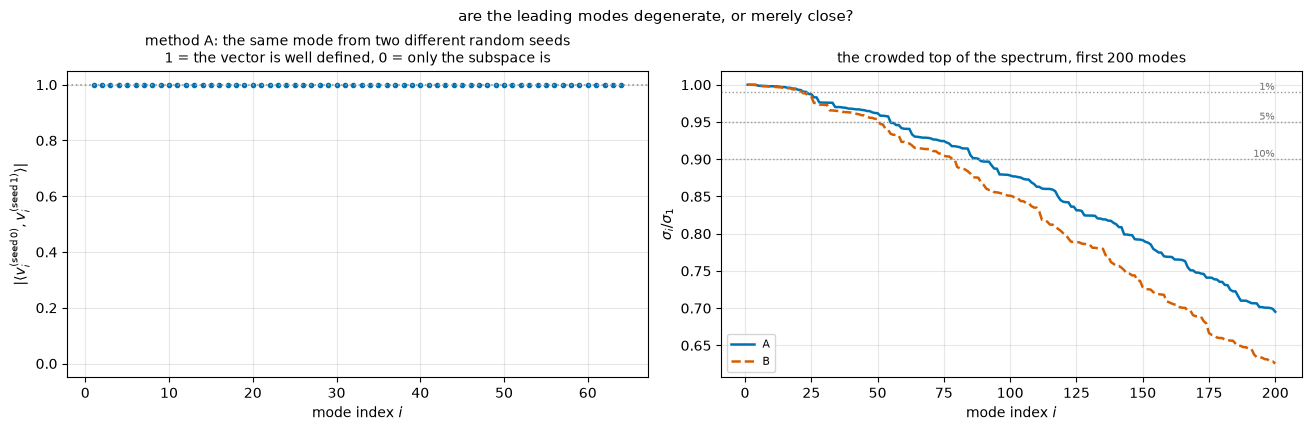


seed overlap of the first 64 modes: median 1.0000, min 0.9999
   -> the vectors are reproducible, so the individual mode pictures in notebook 02
      are legible; the values are crowded, not degenerate.


In [9]:
print(f"{'':36s} {'within 0.1%':>12s} {'1%':>8s} {'5%':>8s} {'10%':>8s}   of sigma_1")
for key in present:
    counts = results[key]["degeneracy"]
    print(f"{results[key]['name']:36s} {counts[0.001]:12d} {counts[0.01]:8d} "
          f"{counts[0.05]:8d} {counts[0.1]:8d}")

area_ratio = n_window_pixels / e.n_object_pixels
print(f"\nwindow / whole-object area ratio : {area_ratio:.4f}")
print("cluster size at the whole grid, scaled by that ratio, against the window's own:")
for tol in (0.01, 0.05, 0.1):
    print(f"   within {tol:.0%} of sigma_1 : {results['A']['degeneracy'][tol]:4d} x "
          f"{area_ratio:.4f} = {results['A']['degeneracy'][tol] * area_ratio:6.1f}"
          f"   vs {results['B']['degeneracy'][tol]:4d} measured in the window")

fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.2), constrained_layout=True)
axes[0].plot(np.arange(1, len(seed_overlap) + 1), seed_overlap, ".", color="#0072B2")
axes[0].axhline(1.0, color="#999999", linestyle=":", linewidth=1.2)
axes[0].set_ylim(-0.05, 1.05)
axes[0].set_xlabel("mode index $i$")
axes[0].set_ylabel("$|\\langle v_i^{(\\mathrm{seed}\\,0)}, v_i^{(\\mathrm{seed}\\,1)}\\rangle|$")
axes[0].set_title("method A: the same mode from two different random seeds\n"
                  "1 = the vector is well defined, 0 = only the subspace is", fontsize=10)
axes[0].grid(alpha=0.3)

for key in present:
    colour, dash = styles[key]
    sigma = results[key]["sigma"]
    axes[1].plot(np.arange(1, min(len(sigma), 200) + 1), (sigma / sigma[0])[:200],
                 linestyle=dash, color=colour, linewidth=1.8, label=key)
for tol in (0.01, 0.05, 0.1):
    axes[1].axhline(1.0 - tol, color="#999999", linestyle=":", linewidth=1.0)
    axes[1].annotate(f"{tol:.0%}", (200, 1.0 - tol), fontsize=7, ha="right", va="bottom",
                     color="#777777")
axes[1].set_xlabel("mode index $i$"); axes[1].set_ylabel("$\\sigma_i/\\sigma_1$")
axes[1].set_title("the crowded top of the spectrum, first 200 modes", fontsize=10)
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
fig.suptitle("are the leading modes degenerate, or merely close?", fontsize=11)
plt.show()

print(f"\nseed overlap of the first {len(seed_overlap)} modes: "
      f"median {np.median(seed_overlap):.4f}, min {seed_overlap.min():.4f}")
print("   -> the vectors are reproducible, so the individual mode pictures in notebook 02")
print("      are legible; the values are crowded, not degenerate.")

## What the $k$ cap costs

Notebook 02 keeps the top $k = 1024$ of $63\,001$ modes and plots $D(q)$ from them. Method B has
every mode of its own domain, so it can answer on its own what truncating at $k$ discards -
inside the window.

**Read the transfer with care.** The cap costs little here because of where $\sigma_k/\sigma_1$
lands, not because of the number 1024. The window's spectrum has decayed much further by its
1024th mode than the whole-object spectrum has by its own, so this control bounds the error
*in the window* and is only suggestive for the whole grid. The two cut depths are printed
together below so the gap between them is visible rather than assumed.

In [10]:
n_cap = min(N_MODES, len(results["B"]["sigma"]))
density_capped = spectral.sensitivity_density(results["B"]["modes"][:n_cap],
                                              results["B"]["sigma"][:n_cap],
                                              results["B"]["origin"])
density_capped_radial = spectral.angular_integral(density_capped)
complete_total = results["B"]["density"].sum()

print(f"method B, complete ({len(results['B']['sigma'])} modes) vs capped at k = {n_cap}")
print(f"   sum D  complete : {complete_total:.6e}   "
      f"(= ||A_window||_F^2 = {results['B']['frobenius']:.6e})")
print(f"   sum D  capped   : {density_capped.sum():.6e}   "
      f"({density_capped.sum() / complete_total:.4%} of it)")
print()
print("where each spectrum is cut at k = 1024:")
print(f"   window      (B) : sigma_k/sigma_1 = "
      f"{results['B']['sigma'][n_cap - 1] / results['B']['sigma'][0]:.4f}")
print(f"   whole grid  (A) : sigma_k/sigma_1 = "
      f"{results['A']['sigma'][-1] / results['A']['sigma'][0]:.4f}"
      f"   <- {results['A']['sigma'][-1] / results['A']['sigma'][0] / (results['B']['sigma'][n_cap - 1] / results['B']['sigma'][0]):.0f}x deeper into the spectrum")
print("\nSo B's 99.99% is a statement about the window, not a licence to assume the same")
print("of the whole grid.  The direct test for the whole grid is tr(A^T A) = ||A||_F^2,")
print("which needs no eigendecomposition - it is one FFT per position - and is not done here.")

method B, complete (8836 modes) vs capped at k = 1024
   sum D  complete : 7.235733e-03   (= ||A_window||_F^2 = 7.235733e-03)
   sum D  capped   : 7.235466e-03   (99.9963% of it)

where each spectrum is cut at k = 1024:
   window      (B) : sigma_k/sigma_1 = 0.0048
   whole grid  (A) : sigma_k/sigma_1 = 0.0669   <- 14x deeper into the spectrum

So B's 99.99% is a statement about the window, not a licence to assume the same
of the whole grid.  The direct test for the whole grid is tr(A^T A) = ||A||_F^2,
which needs no eigendecomposition - it is one FFT per position - and is not done here.


## What weighting by $\sigma^2$ changed

Notebook 02 plots one frequency-domain quantity, $D(q) = \sum_i\sigma_i^2|\hat v_i(q)|^2$. An
earlier version of it plotted a *thresholded, unweighted* sum instead,

$$S_\tau(\mathbf q) = \sum_{i\,:\,\sigma_i > \tau\sigma_1}\left|\hat v_i(\mathbf q)\right|,$$

which reports where the retained subspace *lives* rather than how strongly the experiment
responds there: the last mode admitted at $\tau = 0.1$ responds ten times more weakly than the
first and contributes exactly as much. The threshold is doing all the weighting, as a step
function, and the number of modes it admits is an artefact of where the cut lands.

Three curves are compared below - unweighted $S_\tau$, $\sigma$-weighted, and the
$\sigma^2$-weighted $D$ - with their peaks and half-maximum bands. The expectation, stated before
the plot: weighting should pull the apparent content **down** in frequency, because the high-$\bar q$
modes are precisely the weak ones and $\sigma^2$ punishes them twice.

quantity                                   peak          half-max band   [1/A]
A : unweighted S, tau=0.1 (763 modes)     1.100      0.436 -    1.183
A : sigma-weighted amplitude              0.726      0.353 -    1.100
A : sigma^2-weighted density D            0.560      0.394 -    0.892

B : unweighted S, tau=0.1 (397 modes)     1.100      0.560 -    1.224
B : sigma-weighted amplitude              0.726      0.394 -    1.141
B : sigma^2-weighted density D            0.560      0.394 -    0.934



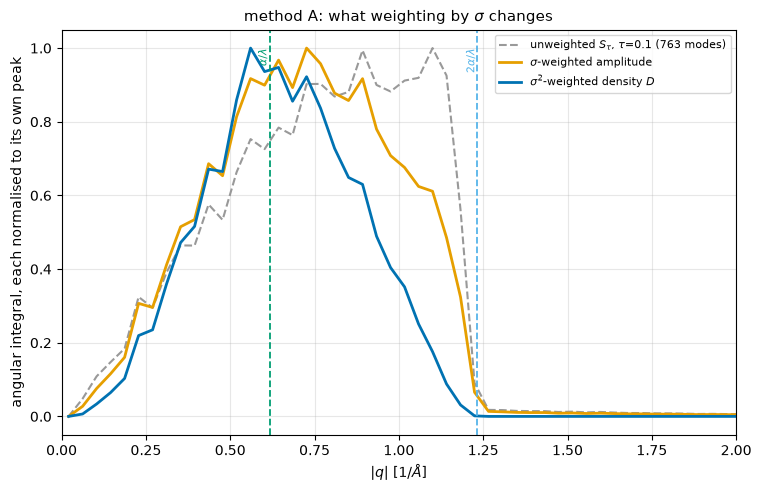

In [11]:
unweighted, weighted_amplitude = {}, {}
for key in present:
    result = results[key]
    indices = np.flatnonzero(result["sigma"] > SIGMA_THRESHOLDS[1] * result["sigma"][0])
    unweighted[key] = spectral.angular_integral(
        spectral.mode_sum_amplitude(result["modes"], result["origin"], indices=indices))
    weighted_amplitude[key] = spectral.angular_integral(
        spectral.mode_sum_amplitude(result["modes"], result["origin"], sigma=result["sigma"]))
    result["tau_count"] = len(indices)

bins = spectral.bin_centres_inv_ang
print(f"{'quantity':38s} {'peak':>8s} {'half-max band':>22s}   [1/A]")
for key in present:
    for label, profile in [
        (f"unweighted S, tau={SIGMA_THRESHOLDS[1]} ({results[key]['tau_count']} modes)",
         unweighted[key]),
        ("sigma-weighted amplitude", weighted_amplitude[key]),
        ("sigma^2-weighted density D", results[key]["density_radial"]),
    ]:
        peak, low, high = sju.half_power_band(profile, bins)
        print(f"{key + ' : ' + label:38s} {peak:8.3f} {low:10.3f} - {high:8.3f}")
    print()

fig, ax = plt.subplots(figsize=(7.5, 4.8), constrained_layout=True)
for label, profile, colour, dash in [
    (f"unweighted $S_\\tau$, $\\tau$={SIGMA_THRESHOLDS[1]} "
     f"({results['A']['tau_count']} modes)", unweighted["A"], "#999999", "--"),
    ("$\\sigma$-weighted amplitude", weighted_amplitude["A"], "#E69F00", "-"),
    ("$\\sigma^2$-weighted density $D$", results["A"]["density_radial"], "#0072B2", "-"),
]:
    ax.plot(bins, profile / profile.max(), linestyle=dash, color=colour,
            linewidth=2.0 if dash == "-" else 1.5, label=label)
for frequency, colour, label in [
    (e.aperture_radius_inv_ang, "#009E73", "$\\alpha/\\lambda$"),
    (2 * e.aperture_radius_inv_ang, "#56B4E9", "$2\\alpha/\\lambda$"),
]:
    ax.axvline(frequency, color=colour, linestyle="--", linewidth=1.3)
    ax.annotate(label, (frequency, 1.0), rotation=90, fontsize=8, ha="right", va="top",
                color=colour)
ax.set_xlim(0, 2.0)
ax.set_xlabel("$|q|$ [1/$\\AA$]")
ax.set_ylabel("angular integral, each normalised to its own peak")
ax.set_title("method A: what weighting by $\\sigma$ changes", fontsize=11)
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()

## The artefact: why B's $D(q)$ must not be read as physics

All three methods agree closely inside the pass band. Past the cliff at $2\alpha/\lambda$ they
do not: A and C fall away to the numerical floor, while **B plateaus three to four decades
above them** and carries that tail straight through the detector edge and the visibility cutoff -
frequencies that physically cannot reach the camera.

That tail is **spectral leakage from the window's hard square edge**. B's modes live on a
$94^2$ window and are exactly zero outside; embedding them on the object grid is lossless in
real space, but the transform of a hard-truncated function is convolved with the boxcar's
separable $\mathrm{sinc}$. Every mode, however low in frequency, picks up $\mathrm{sinc}$ tails
along $q_x$ and $q_y$, and since $D$ accumulates $|\hat v_i(q)|^2$ over modes those tails sum
into a floor. In the 2-D map it is a bright cross along the axes.

Two things establish that it is the window and not the physics:

* **The $k$-cap control sits exactly on top of it.** Dropping 7 812 of B's 8 836 modes leaves
  the tail untouched, so it is not coming from the weak modes that A and C lack.
* **Read as physics it is backwards.** It would say the cropped window retains high-frequency
  sensitivity the whole grid has lost, while Cauchy interlacing says B can only understate.

**So: B is sound for eigenvalues and for the in-band budget, and contaminated along the axes for
anything spectral.** Using the window method for a frequency argument needs an apodised window -
a Tukey or Hann taper before the embedding - or the axis cross masked before the angular integral.

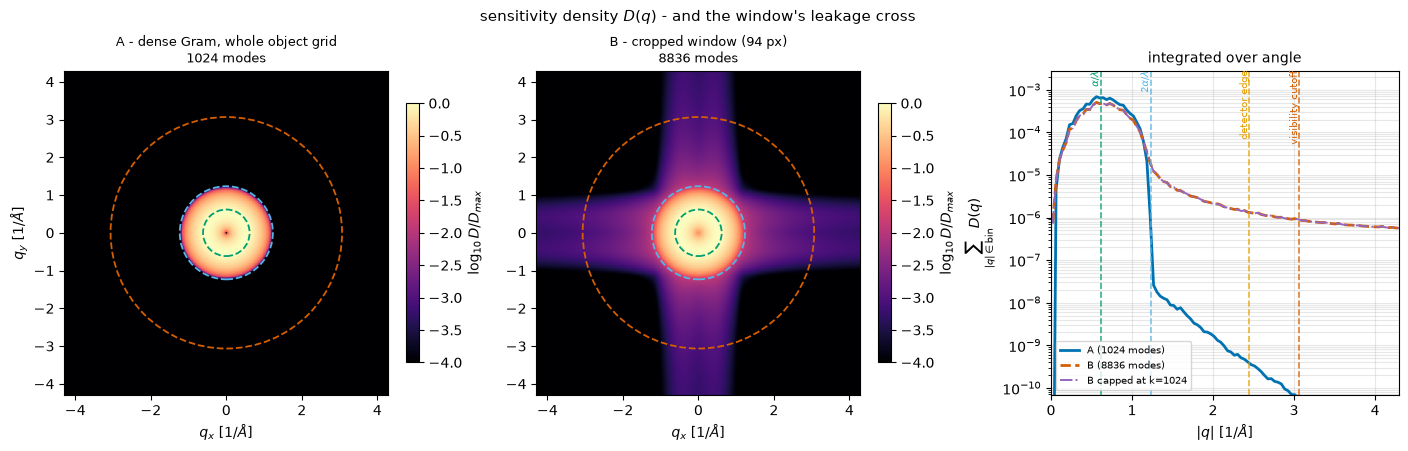

at |q| = 2.01 1/A, well above the 2 alpha/lambda cliff:
   A : 1.619e-09
   B : 2.060e-06
   B capped at k=1024 : 2.040e-06   <- unchanged by the cap, so the tail is the window edge, not the extra modes


In [12]:
view = e.visibility_cutoff_inv_ang * 1.4
fig, axes = plt.subplots(1, len(present) + 1, figsize=(4.7 * (len(present) + 1), 4.4),
                         constrained_layout=True)

for column, key in enumerate(present):
    density = results[key]["density"]
    ax = axes[column]
    handle = ax.imshow(np.log10(np.maximum(density / density.max(), 1e-6)),
                       extent=spectral.extent, origin="lower", cmap="magma",
                       vmin=-4.0, vmax=0.0)
    for frequency, colour in [(e.aperture_radius_inv_ang, "#009E73"),
                              (2 * e.aperture_radius_inv_ang, "#56B4E9"),
                              (e.visibility_cutoff_inv_ang, "#D55E00")]:
        ax.add_patch(plt.Circle((0, 0), frequency, fill=False, edgecolor=colour,
                                linewidth=1.3, linestyle="--"))
    ax.set_xlim(-view, view); ax.set_ylim(-view, view)
    ax.set_xlabel("$q_x$ [1/$\\AA$]")
    if column == 0:
        ax.set_ylabel("$q_y$ [1/$\\AA$]")
    ax.set_title(f"{results[key]['name']}\n{len(results[key]['sigma'])} modes", fontsize=9)
    fig.colorbar(handle, ax=ax, shrink=0.8, label="$\\log_{10} D/D_{max}$")

ax = axes[-1]
for key in present:
    colour, dash = styles[key]
    ax.semilogy(bins, results[key]["density_radial"], linestyle=dash, color=colour,
                linewidth=2.0, label=f"{key} ({len(results[key]['sigma'])} modes)")
ax.semilogy(bins, density_capped_radial, linestyle="-.", color="#9467bd", linewidth=1.4,
            label=f"B capped at k={n_cap}")
for frequency, colour, label in [
    (e.aperture_radius_inv_ang, "#009E73", "$\\alpha/\\lambda$"),
    (2 * e.aperture_radius_inv_ang, "#56B4E9", "$2\\alpha/\\lambda$"),
    (e.detector_edge_inv_ang, "#E69F00", "detector edge"),
    (e.visibility_cutoff_inv_ang, "#D55E00", "visibility cutoff"),
]:
    ax.axvline(frequency, color=colour, linestyle="--", linewidth=1.2, alpha=0.8)
    ax.annotate(label, (frequency, ax.get_ylim()[1]), rotation=90, fontsize=7,
                ha="right", va="top", color=colour)
ax.set_ylim(max(results["A"]["density_radial"].max() * 1e-7, 1e-30), None)
ax.set_xlim(0, view)
ax.set_xlabel("$|q|$ [1/$\\AA$]")
ax.set_ylabel("$\\sum_{|q| \\in \\mathrm{bin}} D(q)$")
ax.set_title("integrated over angle", fontsize=10)
ax.legend(fontsize=7, loc="lower left"); ax.grid(alpha=0.3, which="both")
fig.suptitle("sensitivity density $D(q)$ - and the window's leakage cross", fontsize=11)
plt.show()

cross_q = 2.0
cross_bin = int(np.argmin(np.abs(bins - cross_q)))
print(f"at |q| = {bins[cross_bin]:.2f} 1/A, well above the 2 alpha/lambda cliff:")
for key in present:
    print(f"   {key} : {results[key]['density_radial'][cross_bin]:.3e}")
print(f"   B capped at k={n_cap} : {density_capped_radial[cross_bin]:.3e}"
      "   <- unchanged by the cap, so the tail is the window edge, not the extra modes")

## Summary

What this notebook establishes about notebook 02's figures:

* The modes are the **operator's**, not the algorithm's. Where two methods share a domain
  they agree to five digits in $\sigma_1$, and both bounds that relate the three hold.
* The leading singular values are **crowded but not degenerate**: the vectors reproduce across
  independent random seeds, so the individual mode pictures are legible.
* The **$k$ cap is cheap inside the window** and is *not* thereby shown to be cheap on the whole
  grid, because the two spectra are cut at very different depths. The direct test is the trace.
* **$D(q)$ from methods A and C is clean**; B's is contaminated along the axes by the window's
  hard edge and must not be used for a frequency argument unapodised.
* The arithmetic floors are a statement about **precision, not physics**: forming a Gram spends
  half the digits, so A reports down to $10^{-5}\sigma_1$ and B to $10^{-8}\sigma_1$ and no
  further. Read the position of the roll-off in $\bar q$, which is stable, rather than the exact
  rank.

In [13]:
print(f"{'method':38s} {'domain [px]':>13s} {'modes':>8s} {'complete':>9s} "
      f"{'sigma_1':>12s} {'time [s]':>9s}")
for key in present:
    result = results[key]
    print(f"{result['name']:38s} {result['n_domain']:13,d} {len(result['sigma']):8d} "
          f"{str(result['complete']):>9s} {result['sigma'][0]:12.4e} {result['seconds']:9.1f}")
print()
for key in present:
    print(f"   {key}: {results[key]['notes']}")

print(f"\nscan        : {e.scan_shape} = {e.n_scan_positions} positions at "
      f"{e.realised_scan_step_ang:.3f} A over {config.scan_region_start} to "
      f"{config.scan_region_end} A")
print(f"band limits : aperture {e.aperture_radius_inv_ang:.3f}, "
      f"2 alpha/lambda {2 * e.aperture_radius_inv_ang:.3f}, "
      f"detector edge {e.detector_edge_inv_ang:.3f}, "
      f"visibility cutoff {e.visibility_cutoff_inv_ang:.3f} 1/A")
for key, ratio in ratios.items():
    print(f"bound       : max {key}/A = {ratio.max():.6f}  (must be <= 1)")
if "C" not in results:
    print("\nNOTE: method C was skipped - rerun with a free GPU to complete the comparison.")

method                                   domain [px]    modes  complete      sigma_1  time [s]
A - dense Gram, whole object grid             63,001     1024     False   6.5109e-03     705.2
B - cropped window (94 px)                     8,836     8836      True   6.5050e-03     219.7

   A: float32, 1024 of 63,001 modes
   B: float64, complete spectrum

scan        : (20, 20) = 400 positions at 0.500 A over (7.0, 7.0) to (17.0, 17.0) A
band limits : aperture 0.617, 2 alpha/lambda 1.233, detector edge 2.449, visibility cutoff 3.065 1/A
bound       : max B/A = 0.999090  (must be <= 1)

NOTE: method C was skipped - rerun with a free GPU to complete the comparison.
